In [ ]:
!pip install optuna

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
! pip install scikeras

In [ ]:
import numpy as np
import pandas as pd
import random
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPClassifier
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, InputLayer, Conv1D, Flatten, LSTM, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from scikeras.wrappers import KerasClassifier

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DL models/df_cleaned.csv')
# df = pd.read_csv('/content/drive/MyDrive/Train/DL models/df_cleaned.csv')


In [ ]:
df.head(2)

,Unnamed: 0,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,...,AGE,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,...,26,25-34,10,6,2.0,1.0,2.4,1.4,1.7,0.1
1,1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,...,46,45-54,3,1,3.0,1.5,3.8,2.2,2.0,1.5


In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
y = df['TARGET'].astype(int)
X = df.drop(columns=['TARGET'])

In [ ]:
# Preprocessing
cat_cols = [
    "ORGANIZATION_TYPE", "NAME_FAMILY_STATUS", "AGE_GROUP"
    # , "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE",
    # "NAME_FAMILY_STATUS", "ORGANIZATION_TYPE","WEEKDAY_APPR_PROCESS_START"
]
num_cols = [col for col in X.columns if col not in cat_cols]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
pca = PCA(n_components=0.95, random_state=SEED)
prep_pca = Pipeline([
    ("pre", preprocessor),
    ("pca", pca)
])

In [ ]:
# Train / Val / Test split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

X_train_pca = prep_pca.fit_transform(X_train)
X_val_pca = prep_pca.transform(X_val)
X_test_pca = prep_pca.transform(X_test)

In [ ]:
# SMOTE
smote = SMOTE(random_state=SEED)
X_train_pca, y_train = smote.fit_resample(X_train_pca, y_train)

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
import numpy as np

In [ ]:
input_dim = X_train_pca.shape[1]

In [ ]:
def build_mlp(units1=64, units2=32, dropout_rate=0.3, lr=1e-3):
    model = Sequential([
        InputLayer(shape=(input_dim,)),
        Dense(units1, activation='relu'),
        Dropout(dropout_rate),
        Dense(units2, activation='relu'),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [ ]:
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score,
    accuracy_score, classification_report
)
from keras.callbacks import Callback, EarlyStopping
from keras.models import model_from_json
import numpy as np
import pickle

class PrintValLossCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        print(f"Epoch {epoch+1}, Val Loss: {logs['val_loss']:.4f}")

def tune_keras(build_fn, param_dist, X_train, y_train, name):
    n_iter = 5
    param_list = list(ParameterSampler(param_dist, n_iter=n_iter, random_state=SEED))

    best_auc = -np.inf
    best_model = None
    best_params = None

    X_train_reshaped = X_train.reshape(-1, input_dim, 1) if len(X_train.shape) == 2 else X_train
    X_val_reshaped = X_val_pca.reshape(-1, input_dim, 1) if len(X_val_pca.shape) == 2 else X_val_pca
    X_test_reshaped = X_test_pca.reshape(-1, input_dim, 1) if len(X_test_pca.shape) == 2 else X_test_pca

    for i, params in enumerate(param_list):
        print(f"\n====================")
        print(f"🔹 Trial {i+1}/{n_iter}")
        print(f"Training {name} with params: {params}")

        # Tách batch_size
        batch_size = params.pop("batch_size", 32)

        model = build_fn(**params)

        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        val_loss_logger = PrintValLossCallback()

        history = model.fit(
            X_train_reshaped, y_train,
            epochs=20,
            batch_size=batch_size,
            validation_data=(X_val_reshaped, y_val),
            callbacks=[early_stop, val_loss_logger],
            verbose=0
        )

        print(f"Early stopping at epoch {len(history.history['val_loss'])}")

        print(f"Evaluating {name} on validation set")

        val_probs = model.predict(X_val_reshaped).flatten()

        # tìm threshold tốt nhất trên tập validation
        thresholds = np.arange(0.1, 0.9, 0.01)
        f1_scores = [f1_score(y_val, val_probs > t) for t in thresholds]
        best_threshold = thresholds[np.argmax(f1_scores)]

        val_preds = (val_probs > best_threshold).astype(int)
        val_auc = roc_auc_score(y_val, val_probs)
        val_gini = 2 * val_auc - 1
        val_acc = accuracy_score(y_val, val_preds)

        print(f"Best threshold: {best_threshold:.2f}")
        print(f"Validation Accuracy: {val_acc}")
        print(f"ROC AUC: {val_auc}")
        print(f"Gini Coefficient: {val_gini}")
        print(classification_report(y_val, val_preds, digits=2))

        if val_auc > best_auc:
            best_auc = val_auc
            best_model = model
            best_params = params.copy()
            best_params["batch_size"] = batch_size
            best_params["threshold"] = best_threshold

    print(f"\n===== Best {name} Model =====")
    print("Best params:", best_params)
    print("Best Val AUC:", best_auc)

    test_probs = best_model.predict(X_test_reshaped).flatten()
    test_preds = (test_probs > best_params["threshold"]).astype(int)

    test_auc = roc_auc_score(y_test, test_probs)
    test_acc = accuracy_score(y_test, test_preds)
    test_gini = 2 * test_auc - 1

    print("\n--- Test Set Metrics ---")
    print(f"Test Accuracy: {test_acc}")
    print(f"ROC AUC: {test_auc}")
    print(f"Gini Coefficient: {test_gini}")
    print(classification_report(y_test, test_preds, digits=2))

    model_data = {
        "model_json": best_model.to_json(),
        "model_weights": best_model.get_weights(),
        "best_params": best_params,
        "val_auc": best_auc
    }

    with open(f"{name}_xai_model.pkl", "wb") as f:
        pickle.dump(model_data, f)

    print(f"\n✅ Best model and params saved to {name}_xai_model.pkl")

    return best_model, best_params


In [ ]:
param_dist_mlp = {
    "units1": [64],
    "units2": [32],
    "lr": [0.0001],
    "dropout_rate": [0.4],
    "batch_size": [64]
}

model_mlp, best_params_mlp = tune_keras(build_mlp, param_dist_mlp, X_train_pca, y_train, "MLP")


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=5. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



🔹 Trial 1/5
Training MLP with params: {'units2': 32, 'units1': 64, 'lr': 0.0001, 'dropout_rate': 0.4, 'batch_size': 64}
Epoch 1, Val Loss: 0.6206
Epoch 2, Val Loss: 0.6139
Epoch 3, Val Loss: 0.6079
Epoch 4, Val Loss: 0.6044
Epoch 5, Val Loss: 0.6017
Epoch 6, Val Loss: 0.6035
Epoch 7, Val Loss: 0.6011
Epoch 8, Val Loss: 0.6030
Epoch 9, Val Loss: 0.5974
Epoch 10, Val Loss: 0.5978
Epoch 11, Val Loss: 0.5958
Epoch 12, Val Loss: 0.5941
Epoch 13, Val Loss: 0.5934
Epoch 14, Val Loss: 0.5913
Epoch 15, Val Loss: 0.5906
Epoch 16, Val Loss: 0.5907
Epoch 17, Val Loss: 0.5923
Epoch 18, Val Loss: 0.5893
Epoch 19, Val Loss: 0.5839
Epoch 20, Val Loss: 0.5889
Early stopping at epoch 20
Evaluating MLP on validation set
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
Best threshold: 0.65
Validation Accuracy: 0.8214801071943929
ROC AUC: 0.7338830438382454
Gini Coefficient: 0.46776608767649086
              precision    recall  f1-score   support

           0       0.94      0.86      0.90     53443
         

In [ ]:
def build_cnn1d(filters=64, kernel_size=3, dense_units=64, dropout_rate=0.3, lr=1e-3):
    model = Sequential([
        InputLayer(input_shape=(input_dim, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu"),
        Flatten(),
        Dense(dense_units, activation="relu"),
        Dropout(dropout_rate),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [ ]:
param_dist_cnn = {
    "filters": [64],
    "kernel_size": [3],
    "dense_units": [32],
    "dropout_rate": [0.3],
    "lr": [0.0001],
    "batch_size": [128]
}


In [ ]:
model_cnn, best_params_cnn = tune_keras(build_cnn1d, param_dist_cnn, X_train_pca, y_train, "CNN1D")


🔹 Trial 1/5
Training CNN1D with params: {'lr': 0.0001, 'kernel_size': 3, 'filters': 64, 'dropout_rate': 0.3, 'dense_units': 32, 'batch_size': 128}


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=5. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Epoch 1, Val Loss: 0.6029
Epoch 2, Val Loss: 0.6037
Epoch 3, Val Loss: 0.6043
Epoch 4, Val Loss: 0.6088
Epoch 5, Val Loss: 0.6133
Epoch 6, Val Loss: 0.6032
Early stopping at epoch 6
Evaluating CNN1D on validation set
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
Best threshold: 0.66
Validation Accuracy: 0.8194358551501408
ROC AUC: 0.7316007950055509
Gini Coefficient: 0.4632015900111017
              precision    recall  f1-score   support

           0       0.94      0.85      0.90     53443
           1       0.21      0.43      0.28      4769

    accuracy                           0.82     58212
   macro avg       0.58      0.64      0.59     58212
weighted avg       0.88      0.82      0.85     58212


===== Best CNN1D Model =====
Best params: {'lr': 0.0001, 'kernel_size': 3, 'filters': 64, 'dropout_rate': 0.3, 'dense_units': 32, 'batch_size': 128, 'threshold': np.float64(0.6599999999999997)}
Best Val AUC: 0.7316007950055509
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step

--- Test Set Me

In [ ]:
def build_lstm(units=64, dense_units=64, dropout_rate=0.3, lr=1e-3):
    model = Sequential([
        InputLayer(input_shape=(input_dim, 1)),
        LSTM(units),
        Dense(dense_units, activation="relu"),
        Dropout(dropout_rate),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [ ]:
def build_lstm(units=64, dense_units=64, dropout_rate=0.3, lr=1e-3):
    model = Sequential([
        InputLayer(input_shape=(input_dim, 1)),
        LSTM(units),
        Dense(dense_units, activation="relu"),
        Dropout(dropout_rate),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [ ]:
# Best params
param_dist_lstm = {
    "units": [32],
    "dense_units": [64],
    "dropout_rate": [0.3],
    "lr": [0.0005],
    "batch_size": [128]
}

In [ ]:
model_lstm, best_params_lstm = tune_keras(build_lstm, param_dist_lstm, X_train_pca, y_train, "LSTM")



🔹 Trial 1/5
Training LSTM with params: {'units': 32, 'lr': 0.0005, 'dropout_rate': 0.3, 'dense_units': 64, 'batch_size': 128}


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=5. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Epoch 1, Val Loss: 0.6936
Epoch 2, Val Loss: 0.6427
Epoch 3, Val Loss: 0.6395
Epoch 4, Val Loss: 0.6413
Epoch 5, Val Loss: 0.6379
Epoch 6, Val Loss: 0.6276
Epoch 7, Val Loss: 0.6299
Epoch 8, Val Loss: 0.6362
Epoch 9, Val Loss: 0.6159
Epoch 10, Val Loss: 0.6257
Epoch 11, Val Loss: 0.6244
Epoch 12, Val Loss: 0.6262
Epoch 13, Val Loss: 0.6217
Epoch 14, Val Loss: 0.6328
Early stopping at epoch 14
Evaluating LSTM on validation set
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Best threshold: 0.64
Validation Accuracy: 0.793049543049543
ROC AUC: 0.7058278535750588
Gini Coefficient: 0.4116557071501177
              precision    recall  f1-score   support

           0       0.94      0.82      0.88     53443
           1       0.18      0.44      0.26      4769

    accuracy                           0.79     58212
   macro avg       0.56      0.63      0.57     58212
weighted avg       0.88      0.79      0.83     58212


===== Best LSTM Model =====
Best params: {'units': 32, 'lr': 0.0005, 'drop

In [ ]:
def build_bilstm(units=64, dense_units=64, dropout_rate=0.3, lr=1e-3):
    model = Sequential([
        InputLayer(input_shape=(input_dim, 1)),
        Bidirectional(LSTM(units)),
        Dense(dense_units, activation="relu"),
        Dropout(dropout_rate),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [ ]:
param_dist_bilstm = {
    "units": [32],
    "dense_units": [64],
    "dropout_rate": [0.3],
    "lr": [0.0005],
    "batch_size": [128]
}


In [ ]:
model_bilstm, best_params_bilstm = tune_keras(build_bilstm, param_dist_bilstm, X_train_pca, y_train, "BiLSTM")


🔹 Trial 1/5
Training BiLSTM with params: {'units': 32, 'lr': 0.0005, 'dropout_rate': 0.3, 'dense_units': 64, 'batch_size': 128}


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=5. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Epoch 1, Val Loss: 0.6632
Epoch 2, Val Loss: 0.6324
Epoch 3, Val Loss: 0.6035
Epoch 4, Val Loss: 0.5966
Epoch 5, Val Loss: 0.5968
Epoch 6, Val Loss: 0.5986
Epoch 7, Val Loss: 0.5936
Epoch 8, Val Loss: 0.5919
Epoch 9, Val Loss: 0.5906
Epoch 10, Val Loss: 0.6096
Epoch 11, Val Loss: 0.6060
Epoch 12, Val Loss: 0.6193
Epoch 13, Val Loss: 0.6137
Epoch 14, Val Loss: 0.6108
Early stopping at epoch 14
Evaluating BiLSTM on validation set
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Best threshold: 0.67
Validation Accuracy: 0.8214972857830001
ROC AUC: 0.7086331148225654
Gini Coefficient: 0.4172662296451308
              precision    recall  f1-score   support

           0       0.94      0.86      0.90     53443
           1       0.20      0.40      0.27      4769

    accuracy                           0.82     58212
   macro avg       0.57      0.63      0.58     58212
weighted avg       0.88      0.82      0.85     58212


===== Best BiLSTM Model =====
Best params: {'units': 32, 'lr': 0.0005, 

1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step


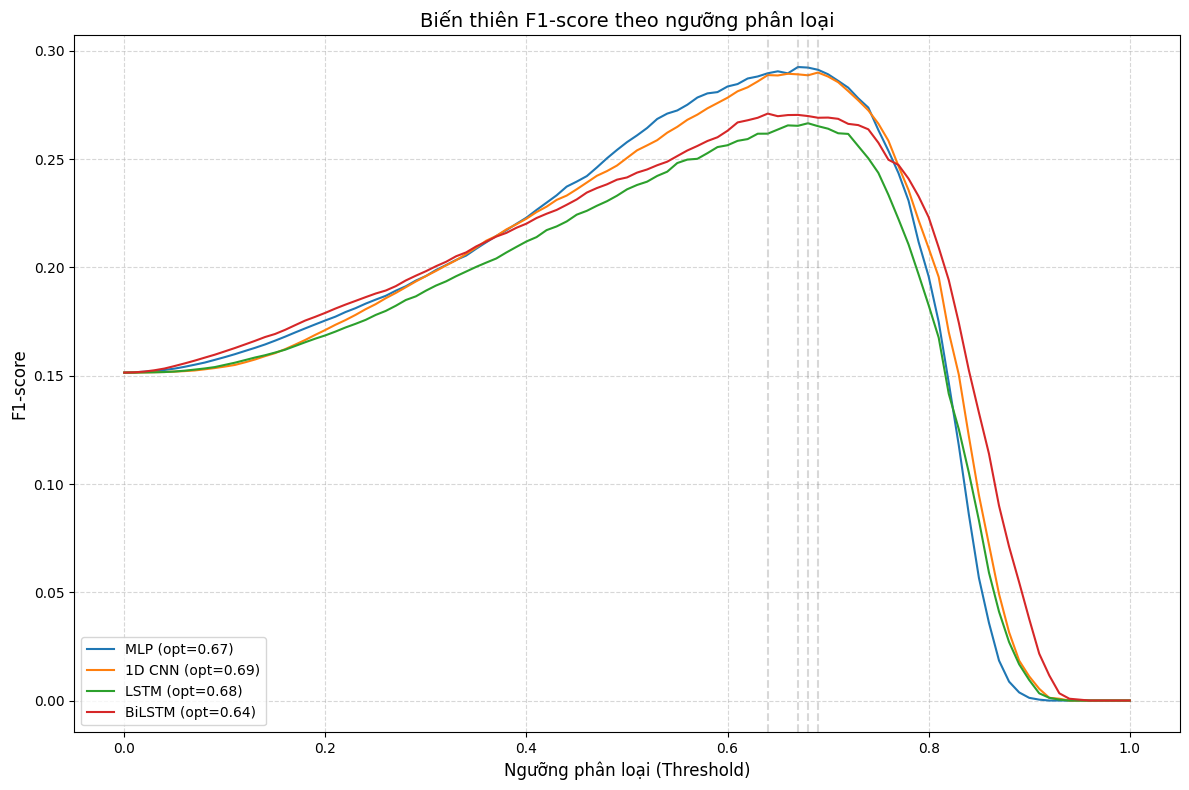

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Tạo thư mục lưu hình nếu chưa có
os.makedirs("figures", exist_ok=True)

# Danh sách mô hình và tên tương ứng
models = {
    "MLP": model_mlp,
    "1D CNN": model_cnn,
    "LSTM": model_lstm,
    "BiLSTM": model_bilstm  # mô hình tốt nhất đã được train từ tune_keras
}

# Ngưỡng từ 0.0 đến 1.0 với bước 0.01
thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(12, 8))

for name, model in models.items():
    # Chuẩn hóa đầu vào cho mô hình Keras
    X_test_reshaped = X_test_pca.reshape(-1, input_dim, 1) if len(X_test_pca.shape) == 2 else X_test_pca

    # Dự đoán xác suất
    y_proba = model.predict(X_test_reshaped).flatten()

    # Tính F1-score theo từng threshold
    f1s = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]

    # Tìm ngưỡng tối ưu
    opt_idx = np.argmax(f1s)
    optimal_threshold = thresholds[opt_idx]
    max_f1 = f1s[opt_idx]

    # Vẽ đường F1 theo threshold
    plt.plot(thresholds, f1s, label=f"{name} (opt={optimal_threshold:.2f})")
    plt.axvline(optimal_threshold, linestyle="--", color='gray', alpha=0.3)

# Hoàn thiện biểu đồ
plt.xlabel("Ngưỡng phân loại (Threshold)", fontsize=12)
plt.ylabel("F1-score", fontsize=12)
plt.title("Biến thiên F1-score theo ngưỡng phân loại", fontsize=14)
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Lưu hình
plt.savefig("figures/threshold_f1_bilstm.pdf", dpi=300)
plt.show()


In [ ]:
import pandas as pd

# Dictionary lưu best threshold và F1 tương ứng cho từng mô hình
best_thresholds = {}
best_f1_scores = {}

for name, model in models.items():
    # Reshape lại nếu là mô hình Keras
    X_test_reshaped = X_test_pca.reshape(-1, input_dim, 1) if len(X_test_pca.shape) == 2 else X_test_pca
    y_proba = model.predict(X_test_reshaped).flatten()

    # Tính F1 theo các threshold
    f1s = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]
    opt_idx = np.argmax(f1s)

    # Lưu kết quả
    best_thresholds[name] = thresholds[opt_idx]
    best_f1_scores[name] = f1s[opt_idx]

# Tạo DataFrame để hiển thị đẹp
results_df = pd.DataFrame({
    "Model": list(best_thresholds.keys()),
    "Optimal Threshold": [f"{best_thresholds[m]:.2f}" for m in best_thresholds],
    "Best F1-score": [f"{best_f1_scores[m]:.4f}" for m in best_f1_scores]
})

# Hiển thị bảng kết quả
print("\n📊 Kết quả tối ưu theo F1-score:")
print(results_df.to_string(index=False))


1820/1820 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
1820/1820 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step

📊 Kết quả tối ưu theo F1-score:
 Model Optimal Threshold Best F1-score
   MLP              0.67        0.2926
1D CNN              0.69        0.2900
  LSTM              0.68        0.2666
BiLSTM              0.64        0.2711
